# 04 · Steered balloons

WindBorne's balloons steer by changing height, because winds at different heights blow in different directions. This notebook asks: **if every site's balloons could steer towards the gap, does Iceland catch up?**

We don't have WindBorne's navigation or their forecasts, so we can't copy how they steer. Instead we **bracket** it with two simple pilots:

| Version | What the pilot knows when choosing | Compared with WindBorne |
|---|---|---|
| **Optimistic ("perfect")** | The real winds of the next 6 hours (hindsight) | Better than any real forecast |
| **Pessimistic ("persistence")** | Only the winds at the moment of decision, assumed to stay the same for 6 hours | Worse than a real forecast |

WindBorne's real forecasts sit between these. **If the site ranking is the same at both ends, the conclusion doesn't depend on how good their steering is.**

**How each pilot works (`fly_steered` in `balloon.py`):**
- Every 6 hours, it predicts the next 6 hours at each height (850, 500 and 250 hPa), using what it knows.
- It picks the height it expects to give the most hours in the gap.
- The balloon then flies the **real** winds at that height.
- When heights tie (common when the gap is more than 6 hours away), there are two tie-break rules:
  - **"stay":** keep the current height. This is the brief's rule; balloons start at 500 hPa.
  - **"closest":** pick the height expected to end closest to the gap.

The limitations of these models are listed at the end of the notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import balloon as b

SITES = {
    "Egilsstaðir":  (65.28, -14.40),
    "Keflavík":     (63.97, -22.60),
    "New York*":    (40.71, -74.01),
    "Cambridge MA": (42.36, -71.09),
    "Juneau":       (58.30, -134.42),
}
COLOURS = dict(zip(SITES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
WINTERS = range(2013, 2022)
LOOKAHEADS = ["persistence", "perfect"]     # pessimistic, optimistic
TIEBREAKS = ["stay", "closest"]

stations = b.active_stations()
dist_km = b.nearest_station_km_grid(stations)
gap_masks = {km: dist_km > km for km in [300, 500, 800]}
region_lats, _ = b.region_grid()
atlantic_500 = gap_masks[500] & (region_lats[:, None] < 60)
arctic_500 = gap_masks[500] & (region_lats[:, None] >= 60)

## 1. Fly every launch with steering

There are 2 pilots × 2 tie-break rules × 3 gap definitions. Each run steers towards *that* gap definition, so the 300 and 800 km results are fair checks. This takes about 5 minutes.

In [2]:
def hours_in(lats, lons, mask, H):
    return b.in_gap(lats[1:H + 1], lons[1:H + 1], mask).sum(axis=0)

rows = []
for winter in WINTERS:
    w = b.load_winter(winter)
    winds = [b.make_wind(w["u"][:, i], w["v"][:, i], w["time"]) for i in range(len(b.LEVELS))]
    days = pd.date_range(f"{winter}-12-01", f"{winter + 1}-03-01", freq="D", inclusive="left")
    names = list(SITES)
    site_idx = np.tile(np.arange(len(names)), len(days))
    day_idx = np.repeat(np.arange(len(days)), len(names))
    lat0 = np.array([SITES[n][0] for n in names])[site_idx]
    lon0 = np.array([SITES[n][1] for n in names])[site_idx]
    t0 = (days.values[day_idx] - w["time"][0]) / np.timedelta64(1, "s")

    for lookahead in LOOKAHEADS:
        for tiebreak in TIEBREAKS:
            for km, mask in gap_masks.items():
                lats, lons, levels = b.fly_steered(winds, lat0, lon0, t0, 21 * 24, mask,
                                                   tiebreak=tiebreak, lookahead=lookahead)
                rec = dict(winter=winter, site=np.array(names)[site_idx], lookahead=lookahead,
                           tiebreak=tiebreak, gap_km=km,
                           gap_7d=hours_in(lats, lons, mask, 168), gap_21d=hours_in(lats, lons, mask, 504))
                if km == 500:
                    rec["atlantic_21d"] = hours_in(lats, lons, atlantic_500, 504)
                    rec["arctic_21d"] = hours_in(lats, lons, arctic_500, 504)
                    for i, lev in enumerate(b.LEVELS):      # share of time at each height
                        rec[f"time_at_{lev}"] = (levels == i).mean(axis=0)
                rows.append(pd.DataFrame(rec))
    print("winter", winter, "done")

steered = pd.concat(rows, ignore_index=True)
steered.to_csv("steered_runs.csv", index=False)
print(len(steered), "steered flights saved to steered_runs.csv")

winter 2013 done
winter 2014 done
winter 2015 done
winter 2016 done
winter 2017 done
winter 2018 done
winter 2019 done
winter 2020 done
winter 2021 done
48720 steered flights saved to steered_runs.csv


## 2. Passive vs steered (500 km gap)

Median gap-hours per launch, with the middle half of launches in brackets. Passive results come from notebook 02.

**"Best fixed height"** is the single height that gave each site its highest median. It's picked after the fact, so it flatters every site equally.

In [3]:
passive = pd.read_csv("passive_runs.csv")
order = list(SITES)

def med_iqr(x):
    return f"{np.median(x):.0f} [{np.percentile(x, 25):.0f}–{np.percentile(x, 75):.0f}]"

table = {}
for hz in ["7d", "21d"]:
    col = f"gap_h_500km_{hz}"
    table[f"passive 500 hPa, {hz}"] = passive[passive.level == 500].groupby("site")[col].apply(med_iqr)
    best = passive.groupby(["site", "level"])[col].median().groupby("site").agg(["max", "idxmax"])
    table[f"best fixed height, {hz}"] = best.apply(lambda r: f"{r['max']:.0f} ({r['idxmax'][1]} hPa)", axis=1)
    for la in LOOKAHEADS:
        for tb in TIEBREAKS:
            s = steered[(steered.gap_km == 500) & (steered.lookahead == la) & (steered.tiebreak == tb)]
            table[f"{la} / {tb}, {hz}"] = s.groupby("site")[f"gap_{hz}"].apply(med_iqr)
pd.DataFrame(table).reindex(order).T

site,Egilsstaðir,Keflavík,New York*,Cambridge MA,Juneau
"passive 500 hPa, 7d",1 [0–9],2 [0–13],14 [1–23],16 [6–25],12 [0–20]
"best fixed height, 7d",7 (850 hPa),13 (850 hPa),25 (850 hPa),24 (850 hPa),12 (250 hPa)
"persistence / stay, 7d",1 [0–16],4 [0–26],18 [2–37],21 [9–39],16 [0–29]
"persistence / closest, 7d",11 [1–32],18 [3–41],31 [18–52],32 [18–54],28 [16–46]
"perfect / stay, 7d",1 [0–18],5 [0–27],19 [2–38],23 [9–42],17 [0–31]
"perfect / closest, 7d",12 [2–33],18 [3–43],31 [18–51],33 [19–54],30 [17–47]
"passive 500 hPa, 21d",12 [0–25],14 [1–30],18 [5–34],20 [10–37],21 [11–35]
"best fixed height, 21d",19 (850 hPa),27 (850 hPa),38 (850 hPa),37 (850 hPa),23 (250 hPa)
"persistence / stay, 21d",20 [2–50],27 [5–58],27 [8–57],31 [15–65],35 [17–63]
"persistence / closest, 21d",43 [15–83],53 [21–93],57 [29–96],56 [30–98],70 [36–108]


## 3. Does the ranking hold at both ends of the bracket, and across gap definitions?

Median gap-hours per launch over 21 days. Ranks: 1 = most hours.

In [4]:
sens = steered.pivot_table(index="site", columns=["lookahead", "tiebreak", "gap_km"],
                           values="gap_21d", aggfunc="median").reindex(order)
display(sens)
print("Ranks (1 = most gap-hours):")
sens.rank(ascending=False, method="min").astype(int)

lookahead    perfect                               persistence              \
tiebreak     closest              stay                 closest               
gap_km           300   500   800   300   500   800         300   500   800   
site                                                                         
Egilsstaðir    111.5  47.0   7.0  83.0  22.0   0.0        92.0  43.0   7.0   
Keflavík       120.0  55.0  11.0  81.0  27.0   0.0       105.0  53.0  11.0   
New York*      103.5  59.0  22.0  60.0  28.0  13.0        99.0  57.0  21.0   
Cambridge MA   109.5  62.0  23.0  72.5  34.0  15.0        99.0  56.0  22.0   
Juneau         121.0  71.0  16.0  74.0  35.5  13.0       117.0  70.0  15.0   

lookahead                       
tiebreak      stay              
gap_km         300   500   800  
site                            
Egilsstaðir   69.0  20.5   0.0  
Keflavík      80.0  27.0   0.0  
New York*     57.0  27.0  12.0  
Cambridge MA  67.0  31.0  15.0  
Juneau        68.0  35.0  13.0

Ranks (1 = most gap-hours):


lookahead    perfect                      persistence                     
tiebreak     closest         stay             closest         stay        
gap_km           300 500 800  300 500 800         300 500 800  300 500 800
site                                                                      
Egilsstaðir        3   5   5    1   5   4           5   5   5    2   5   4
Keflavík           2   4   4    2   4   4           2   4   4    1   3   4
New York*          5   3   2    5   3   2           3   2   2    5   3   3
Cambridge MA       4   2   1    4   2   1           3   3   1    4   2   1
Juneau             1   1   3    3   1   2           1   1   3    3   1   2

## 4. Atlantic part vs Arctic part, steered (500 km gap, 21 days)

These are means, so the two parts add up to the total. The Atlantic part is 45 to 60°N; the Arctic part is 60 to 90°N. (Splitting at 60°N was a choice made after seeing the passive result.)

In [5]:
s500 = steered[steered.gap_km == 500]
idx = pd.MultiIndex.from_product([LOOKAHEADS, TIEBREAKS, order])
split = s500.groupby(["lookahead", "tiebreak", "site"])[["atlantic_21d", "arctic_21d", "gap_21d"]].mean()
split["share_reaching_arctic"] = s500.assign(r=s500.arctic_21d > 0).groupby(
    ["lookahead", "tiebreak", "site"]).r.mean()
display(split.reindex(idx).round(2))
print("Share of flight time spent at each height:")
s500.groupby(["lookahead", "tiebreak", "site"])[[f"time_at_{l}" for l in b.LEVELS]].mean().reindex(idx).round(2)

atlantic_21d  arctic_21d  gap_21d  \
persistence stay    Egilsstaðir          16.92       18.33    35.24   
                    Keflavík             19.85       20.47    40.32   
                    New York*            29.41       10.54    39.94   
                    Cambridge MA         34.33       11.22    45.55   
                    Juneau               30.26       15.99    46.24   
            closest Egilsstaðir          15.17       43.02    58.20   
                    Keflavík             19.86       46.36    66.22   
                    New York*            37.57       33.21    70.78   
                    Cambridge MA         38.39       32.53    70.92   
                    Juneau               33.42       45.90    79.32   
perfect     stay    Egilsstaðir          17.22       19.28    36.49   
                    Keflavík             20.09       21.95    42.04   
                    New York*            29.97       11.83    41.79   
                    Cambridge MA         34.37       14.78    49.15   
                    Juneau               31.66       16.73    48.38   
            closest Egilsstaðir          14.97       49.36    64.33   
                    Keflavík             20.75       48.85    69.61   
                    New York*            38.60       34.86    73.47   
                    Cambridge MA         38.62       35.84    74.46   
                    Juneau               33.73       49.97    83.70   

                                  share_reaching_arctic  
persistence stay    Egilsstaðir                    0.67  
                    Keflavík                       0.71  
                    New York*                      0.43  
                    Cambridge MA                   0.49  
                    Juneau                         0.54  
            closest Egilsstaðir                    0.88  
                    Keflavík                       0.91  
                    New York*                      0.74  
                    Cambridge MA                   0.72  
                    Juneau                         0.83  
perfect     stay    Egilsstaðir                    0.70  
                    Keflavík                       0.74  
                    New York*                      0.46  
                    Cambridge MA                   0.51  
                    Juneau                         0.55  
            closest Egilsstaðir                    0.90  
                    Keflavík                       0.91  
                    New York*                      0.72  
                    Cambridge MA                   0.74  
                    Juneau                         0.86

Share of flight time spent at each height:


time_at_850  time_at_500  time_at_250
persistence stay    Egilsstaðir          0.28         0.57         0.15
                    Keflavík             0.35         0.50         0.15
                    New York*            0.43         0.41         0.16
                    Cambridge MA         0.46         0.40         0.15
                    Juneau               0.39         0.46         0.15
            closest Egilsstaðir          0.58         0.21         0.21
                    Keflavík             0.58         0.21         0.21
                    New York*            0.59         0.21         0.21
                    Cambridge MA         0.59         0.20         0.21
                    Juneau               0.53         0.21         0.26
perfect     stay    Egilsstaðir          0.30         0.56         0.14
                    Keflavík             0.35         0.51         0.14
                    New York*            0.45         0.42         0.13
                    Cambridge MA         0.49         0.38         0.13
                    Juneau               0.40         0.46         0.14
            closest Egilsstaðir          0.60         0.20         0.20
                    Keflavík             0.60         0.20         0.20
                    New York*            0.60         0.20         0.20
                    Cambridge MA         0.60         0.20         0.20
                    Juneau               0.55         0.20         0.24

## 5. Chart: gap-hours per launch by site, passive vs the steering bracket

Dot = median; bar = middle half of launches (25th to 75th percentile). 500 km gap, "closest" tie-break (the "stay" rule is in the tables above).

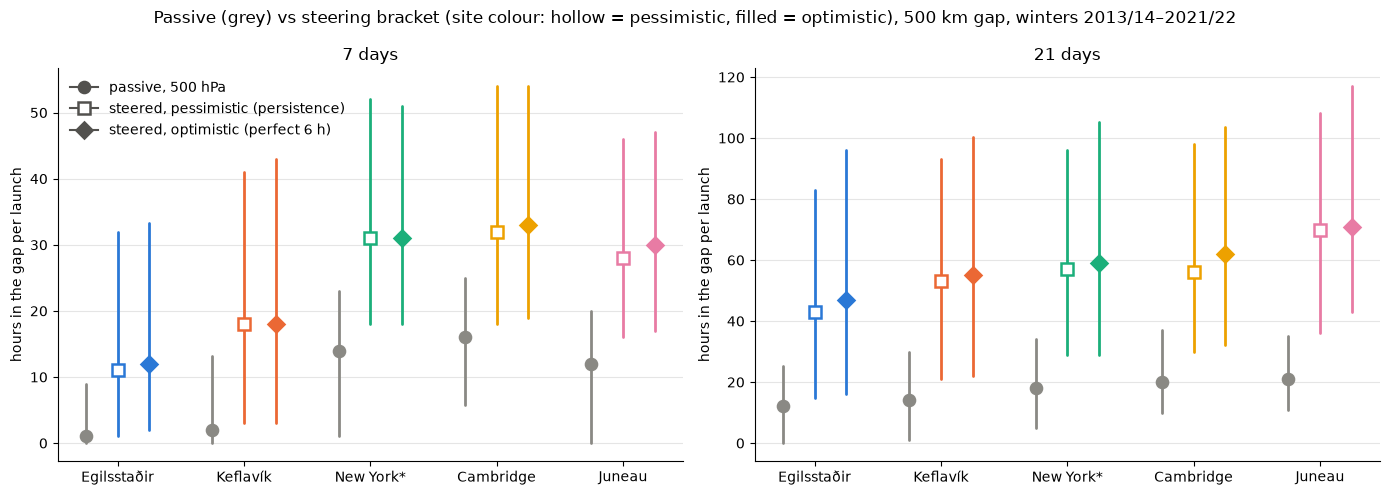

In [6]:
variants = [("passive, 500 hPa", "o", None, True),
            ("steered, pessimistic (persistence)", "s", "persistence", False),
            ("steered, optimistic (perfect 6 h)", "D", "perfect", True)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, hz in zip(axes, ["7d", "21d"]):
    for vi, (label, marker, la, filled) in enumerate(variants):
        for si, site in enumerate(order):
            if la is None:
                x = passive[(passive.level == 500) & (passive.site == site)][f"gap_h_500km_{hz}"]
                colour = "#8a8984"
            else:
                x = s500[(s500.lookahead == la) & (s500.tiebreak == "closest") & (s500.site == site)][f"gap_{hz}"]
                colour = COLOURS[site]
            xpos = si + (vi - 1) * 0.25
            ax.plot([xpos, xpos], np.percentile(x, [25, 75]), color=colour, lw=2, solid_capstyle="round")
            ax.plot(xpos, np.median(x), marker=marker, ms=8, color=colour,
                    markerfacecolor=colour if filled else "white", markeredgewidth=1.8,
                    label=label if si == 0 else None)
    ax.set_xticks(range(len(order)), [s.replace(" MA", "") for s in order])
    ax.set_title(hz.replace("d", " days"))
    ax.set_ylabel("hours in the gap per launch")
    ax.grid(axis="y", color="#e5e5e5"); ax.set_axisbelow(True)
    for side in ["top", "right"]: ax.spines[side].set_visible(False)
leg = axes[0].legend(frameon=False, loc="upper left")
for h, v in zip(leg.legend_handles, variants):          # legend shows marker shape only
    h.set_color("#52514e"); h.set_markerfacecolor("#52514e" if v[3] else "white")
plt.suptitle("Passive (grey) vs steering bracket (site colour: hollow = pessimistic, filled = optimistic), "
             "500 km gap, winters 2013/14–2021/22")
plt.tight_layout(); plt.show()

## 6. Scaling to the fleet (Little's law)

If a site launches **one balloon a day**, and each launch spends on average *H* hours in the gap, then on average **H / 24 of its balloons are in the gap at any moment**. This assumes every flight lasts 21 days, the brief's mean flight, which is a simplification.

For scale: 1 launch a day × 21 days ≈ 21 balloons aloft, about 3% of a 700-balloon fleet.

In [7]:
cl = s500[s500.tiebreak == "closest"]
little = pd.DataFrame({
    "passive 500 hPa": passive[passive.level == 500].groupby("site").gap_h_500km_21d.mean() / 24,
    "steered, pessimistic": cl[cl.lookahead == "persistence"].groupby("site").gap_21d.mean() / 24,
    "steered, optimistic": cl[cl.lookahead == "perfect"].groupby("site").gap_21d.mean() / 24,
}).reindex(order)
print("Average number of balloons in the 500 km gap at any moment, per 1 launch/day ('closest' tie-break):")
little.round(2)

Average number of balloons in the 500 km gap at any moment, per 1 launch/day ('closest' tie-break):


,passive 500 hPa,"steered, pessimistic","steered, optimistic"
site,,,
Egilsstaðir,0.74,2.42,2.68
Keflavík,0.86,2.76,2.90
New York*,0.99,2.95,3.06
Cambridge MA,1.11,2.96,3.10
Juneau,1.12,3.31,3.49


## 7. Limitations of the steering models

**Both pilots**
- **Neither is WindBorne's navigation.** They are two simple pilots chosen to sit either side of it. The comparison between sites is fair because every site gets the same pilot, but the absolute hours are not predictions of real flights.
- **Neither is a strict bound.** Both pilots only look 6 hours ahead and choose greedily. A short-sighted pilot can do worse than one with less information, or worse than simply holding one good height. Real performance "probably lies between" the two; it is not guaranteed to.
- **Only three heights.** Real balloons can float at any height in their range.
- **Instant height changes.** No time to climb or descend.
- **Unlimited ballast and gas.** WindBorne changes height by dropping ballast or venting lift gas, both of which are finite. Our pilots change height as often as every 6 hours for 21 days.
- **250 hPa is about 34,000 ft (FL340).** Since the UA1093 incident, WindBorne balloons no longer hold neutral buoyancy between FL300 and FL400. Our pilots, and the passive 250 hPa runs, float there freely. The 250 hPa results describe a height WindBorne now avoids holding.
- **Every flight lasts exactly 21 days.** There are no early terminations or recoveries.
- **The pilot knows exactly where the gap is,** and steers only for gap-hours. A real pilot also balances airspace, ballast, recovery and customers.
- **The winds are 1.5° reanalysis.** That's coarse for exact routes, but fine for drift on the scale of weather systems.

**The pessimistic pilot ("persistence")**
- **It assumes the winds at every height stay exactly as they are for 6 hours.** In reality weather systems move and change. Near jet streams and fronts, the wind can change a lot in 6 hours.
- **It uses the reanalysis winds at decision time as "what the pilot knows now".** A real pilot only has a forecast model's analysis, which is close to this but not identical, and arrives with a delay.
- **It's the standard baseline any forecast should beat,** but it isn't the worst possible pilot. A random or badly informed pilot would do worse.

**The optimistic pilot ("perfect")**
- **It uses hindsight:** the real winds of the next 6 hours. No forecast is that good.

## What to read off this (Senan writes the findings)

1. At both ends of the bracket, does Iceland catch up with or pass the US sites on total gap-hours?
2. Does the answer depend on the pilot (persistence vs perfect) or on the tie-break rule? If it does, the result is about navigation, not the site.
3. Does Iceland's lead in the Arctic part survive steering?
4. In Little's law terms, how many balloons in the gap does one launch a day buy at each site?